# Vanilla Autoencoder — Fashion-MNIST (Versi Ringkas)

**Tujuan:** baseline untuk komparasi 6 model pada PDF. Tetap mencakup split 80/10/10 (seed 42), training & validation, checkpoint terbaik, **Test MSE / PSNR / SSIM**, **latency batch 64**, **3 grafik**, dan ekspor **CSV**.

Jalankan cell dari atas ke bawah. Kalau ada paket yang belum terinstal, jalankan `%pip install torch torchvision numpy pandas matplotlib scikit-image`.

In [1]:
from pathlib import Path
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import ConcatDataset, Subset, DataLoader
from torchvision import datasets, transforms
from skimage.metrics import structural_similarity as ssim

SEED, BATCH, LATENT, EPOCHS, LR = 42, 128, 64, 15, 1e-3
OUT = Path('outputs/vanilla_ae')
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = Path('fashion_mnist_split_seed42.npz')
MODEL_FILE = OUT / 'best_vanilla_ae.pt'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', device)


Device: cuda


In [2]:
transform = transforms.ToTensor()
full = ConcatDataset([
    datasets.FashionMNIST('data', train=True, download=True, transform=transform),
    datasets.FashionMNIST('data', train=False, download=True, transform=transform),
])

if SPLIT_FILE.exists():
    s = np.load(SPLIT_FILE)
    train_idx, val_idx, test_idx = s['train_idx'], s['val_idx'], s['test_idx']
else:
    idx = torch.randperm(len(full), generator=torch.Generator().manual_seed(SEED)).numpy()
    train_idx, val_idx, test_idx = idx[:56000], idx[56000:63000], idx[63000:]
    np.savez_compressed(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

assert (len(train_idx), len(val_idx), len(test_idx)) == (56000, 7000, 7000)
assert len(np.unique(np.r_[train_idx, val_idx, test_idx])) == len(full)
train_set, val_set, test_set = [Subset(full, ids.tolist()) for ids in
                                (train_idx, val_idx, test_idx)]
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(val_set,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH, shuffle=False)
print('Train / Val / Test:', len(train_set), len(val_set), len(test_set))


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 164kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.04MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.5MB/s]


Train / Val / Test: 56000 7000 7000


## 3. Model — 784 → 256 → 64 → 256 → 784

In [3]:
class VanillaAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, LATENT), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(LATENT, 256), nn.ReLU(),
                                     nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))

model = VanillaAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
num_params = sum(p.numel() for p in model.parameters())
print(f'Jumlah parameter: {num_params:,}')


Jumlah parameter: 435,536


In [4]:
def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()

def run_epoch(loader, training=False):
    model.train(training)
    total_error, total_pixels = 0.0, 0
    with torch.set_grad_enabled(training):
        for x, _ in loader:
            x = x.to(device)
            if training:
                optimizer.zero_grad()
            recon = model(x)
            loss = nn.functional.mse_loss(recon, x)
            if training:
                loss.backward()
                optimizer.step()
            total_error += nn.functional.mse_loss(recon.detach(), x, reduction='sum').item()
            total_pixels += x.numel()
    return total_error / total_pixels

history, best_val, best_epoch = [], float('inf'), 0
for epoch in range(1, EPOCHS + 1):
    sync()
    start = time.perf_counter()
    train_mse = run_epoch(train_loader, training=True)
    sync()
    seconds = time.perf_counter() - start
    val_mse = run_epoch(val_loader)
    history.append({'epoch': epoch, 'train_mse': train_mse,
                    'val_mse': val_mse, 'training_time_s': seconds})
    if val_mse < best_val:
        best_val, best_epoch = val_mse, epoch
        torch.save(model.state_dict(), MODEL_FILE)
    print(f'Epoch {epoch:02} | Train {train_mse:.5f} | Val {val_mse:.5f} | {seconds:.1f}s')

history_df = pd.DataFrame(history)
history_df.to_csv(OUT / 'vanilla_ae_history.csv', index=False)
model.load_state_dict(torch.load(MODEL_FILE, map_location=device, weights_only=True))
model.eval()
print('Best epoch:', best_epoch)


Epoch 01 | Train 0.03465 | Val 0.01980 | 10.6s
Epoch 02 | Train 0.01767 | Val 0.01639 | 6.1s
Epoch 03 | Train 0.01513 | Val 0.01448 | 6.3s
Epoch 04 | Train 0.01358 | Val 0.01335 | 6.4s
Epoch 05 | Train 0.01257 | Val 0.01247 | 5.9s
Epoch 06 | Train 0.01188 | Val 0.01180 | 7.4s
Epoch 07 | Train 0.01133 | Val 0.01154 | 5.9s
Epoch 08 | Train 0.01085 | Val 0.01093 | 6.6s
Epoch 09 | Train 0.01046 | Val 0.01060 | 5.9s
Epoch 10 | Train 0.01013 | Val 0.01030 | 6.5s
Epoch 11 | Train 0.00985 | Val 0.00992 | 6.2s
Epoch 12 | Train 0.00959 | Val 0.00973 | 6.2s
Epoch 13 | Train 0.00938 | Val 0.00953 | 6.7s
Epoch 14 | Train 0.00919 | Val 0.00935 | 5.9s
Epoch 15 | Train 0.00901 | Val 0.00927 | 6.6s
Best epoch: 15


In [5]:
errors, psnr_values, ssim_values = 0.0, [], []
with torch.inference_mode():
    for x, _ in test_loader:
        x = x.to(device)
        recon = model(x)
        errors += nn.functional.mse_loss(recon, x, reduction='sum').item()
        per_image_mse = (recon - x).square().flatten(1).mean(dim=1)
        psnr_values.extend((10 * torch.log10(1 / per_image_mse.clamp_min(1e-12))).cpu().tolist())
        x_np, recon_np = x.cpu().numpy(), recon.cpu().numpy()
        ssim_values.extend(ssim(a[0], b[0], data_range=1.0)
                           for a, b in zip(x_np, recon_np))

test_mse = errors / (len(test_set) * 28 * 28)
test_psnr = float(np.mean(psnr_values))
test_ssim = float(np.mean(ssim_values))

x64 = next(iter(test_loader))[0][:64].to(device)
with torch.inference_mode():
    for _ in range(10):
        model(x64)                       # warmup
    timings = []
    for _ in range(30):
        sync()
        start = time.perf_counter()
        model(x64)
        sync()
        timings.append((time.perf_counter() - start) * 1000)
latency = float(np.mean(timings))
print(f'Test MSE  : {test_mse:.6f}')
print(f'Test PSNR : {test_psnr:.3f} dB')
print(f'Test SSIM : {test_ssim:.4f}')
print(f'Latency   : {latency:.3f} ± {np.std(timings):.3f} ms / batch 64')


Test MSE  : 0.009209
Test PSNR : 21.308 dB
Test SSIM : 0.7715
Latency   : 0.223 ± 0.021 ms / batch 64


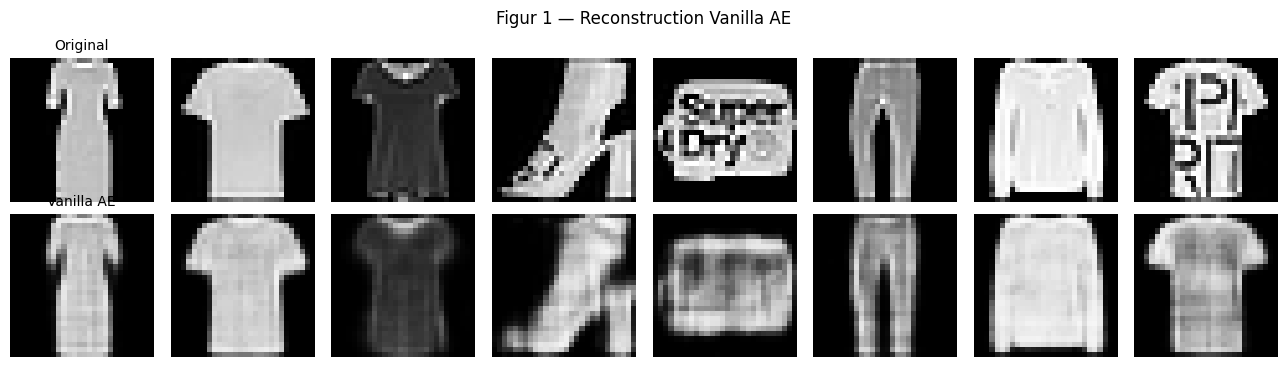

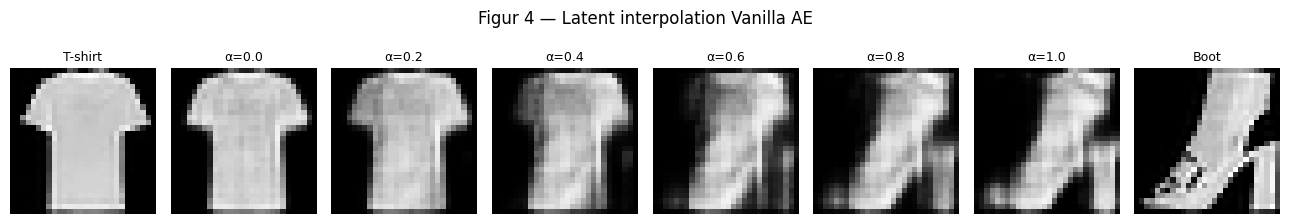

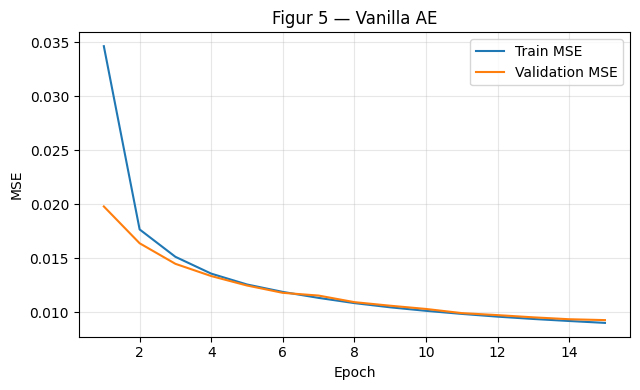

In [6]:
# Figur 1 — Original vs reconstruction (8 gambar)
x8 = next(iter(test_loader))[0][:8].to(device)
with torch.inference_mode():
    recon8 = model(x8).cpu()
fig, axes = plt.subplots(2, 8, figsize=(13, 3.7))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[1, i].imshow(recon8[i, 0], cmap='gray', vmin=0, vmax=1)
    for row in axes:
        row[i].axis('off')
axes[0, 0].set_title('Original', fontsize=10)
axes[1, 0].set_title('Vanilla AE', fontsize=10)
fig.suptitle('Figur 1 — Reconstruction Vanilla AE')
plt.tight_layout()
plt.savefig(OUT / 'figure1_vanilla_ae_reconstruction.png', dpi=200)
plt.show()

# Figur 4 — Latent interpolation (kelas 0 ke kelas 9)
def sample_of_class(target):
    for x, label in test_set:
        if label == target:
            return x.unsqueeze(0).to(device)
    raise ValueError(f'Kelas {target} tidak ditemukan')

x_a, x_b = sample_of_class(0), sample_of_class(9)
alphas = np.linspace(0, 1, 6)
with torch.inference_mode():
    z_a, z_b = model.encode(x_a), model.encode(x_b)
    z = torch.cat([(1-float(a))*z_a + float(a)*z_b for a in alphas])
    images = model.decode(z).cpu()
fig, axes = plt.subplots(1, 8, figsize=(13, 2.4))
for i in range(8):
    img = x_a[0, 0].cpu() if i == 0 else x_b[0, 0].cpu() if i == 7 else images[i-1, 0]
    axes[i].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[i].set_title('T-shirt' if i == 0 else 'Boot' if i == 7 else f'α={alphas[i-1]:.1f}', fontsize=9)
    axes[i].axis('off')
fig.suptitle('Figur 4 — Latent interpolation Vanilla AE')
plt.tight_layout()
plt.savefig(OUT / 'figure4_vanilla_ae_interpolation.png', dpi=200)
plt.show()

# Figur 5 — Loss curves
plt.figure(figsize=(6.5, 4))
plt.plot(history_df['epoch'], history_df['train_mse'], label='Train MSE')
plt.plot(history_df['epoch'], history_df['val_mse'], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Figur 5 — Vanilla AE')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(OUT / 'figure5_vanilla_ae_loss.png', dpi=200)
plt.show()


In [7]:
result = pd.DataFrame([{
    'model': 'Vanilla AE', 'dataset': 'Fashion-MNIST', 'seed': SEED,
    'train_size': len(train_set), 'val_size': len(val_set), 'test_size': len(test_set),
    'latent_dim': LATENT, 'batch_size': BATCH, 'num_parameters': num_params,
    'best_epoch': best_epoch,
    'training_time_epoch_s_mean': history_df['training_time_s'].mean(),
    'inference_latency_batch64_ms': latency,
    'test_mse': test_mse, 'test_psnr_db': test_psnr, 'test_ssim': test_ssim,
    'fid': np.nan,  # N/A pada tabel PDF untuk Vanilla AE
    'device': str(device),
}])
result.to_csv(OUT / 'vanilla_ae_metrics.csv', index=False)
print(result.T.to_string(header=False))
print('File output:', OUT.resolve())


model                            Vanilla AE
dataset                       Fashion-MNIST
seed                                     42
train_size                            56000
val_size                               7000
test_size                              7000
latent_dim                               64
batch_size                              128
num_parameters                       435536
best_epoch                               15
training_time_epoch_s_mean         6.628751
inference_latency_batch64_ms       0.223475
test_mse                           0.009209
test_psnr_db                      21.307581
test_ssim                          0.771498
fid                                     NaN
device                                 cuda
File output: /content/outputs/vanilla_ae


In [8]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [10]:
!cp -r /content/outputs/vanilla_ae "/content/drive/MyDrive/[CN] Colab Notebooks/[CV] Computer Vision/DCGANAE: All Experiments"